## Step 3: Machine learning

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn import cluster, mixture

### Loading the data
We loaded the cleaned data from `01_load_and_clean.ipynb`, and parsed `date_time_utc` as datetime.

In [7]:
%%time
aisdata = pd.read_csv('../data/dataset_clean.csv', parse_dates=['date_time_utc'])

aisdata.head()

CPU times: user 986 ms, sys: 369 ms, total: 1.35 s
Wall time: 2.33 s


,date_time_utc,mmsi,dsrc,imo,ship_name,ship_type,lon,lat,status,rot,speed,cog,true_heading,length,breadth,draught,ais_class,date_utc
0,2025-01-01 00:00:01,219592000,G,8917613,CROWN SEAWAYS,60,10.819025,58.400230,0,-9.0,16.9,155.6,158.0,171,28,6.2,A,2025-01-01
1,2025-01-01 00:00:06,219592000,G,8917613,CROWN SEAWAYS,60,10.819285,58.399872,0,-7.0,16.6,158.8,158.0,171,28,6.2,A,2025-01-01
2,2025-01-01 00:00:18,219592000,G,8917613,CROWN SEAWAYS,60,10.819842,58.399158,0,-12.0,16.2,158.0,157.0,171,28,6.2,A,2025-01-01
3,2025-01-01 00:00:25,219592000,G,8917613,CROWN SEAWAYS,60,10.820135,58.398805,0,8.0,16.5,157.4,157.0,171,28,6.2,A,2025-01-01
4,2025-01-01 00:00:31,219592000,G,8917613,CROWN SEAWAYS,60,10.820700,58.398093,0,-5.0,16.9,158.3,157.0,171,28,6.2,A,2025-01-01


In [8]:
aisdata.shape

(3126297, 18)

In [9]:
aisdata.info()

<class 'pandas.DataFrame'>
RangeIndex: 3126297 entries, 0 to 3126296
Data columns (total 18 columns):
 #   Column         Dtype         
---  ------         -----         
 0   date_time_utc  datetime64[us]
 1   mmsi           int64         
 2   dsrc           str           
 3   imo            int64         
 4   ship_name      str           
 5   ship_type      int64         
 6   lon            float64       
 7   lat            float64       
 8   status         int64         
 9   rot            float64       
 10  speed          float64       
 11  cog            float64       
 12  true_heading   float64       
 13  length         int64         
 14  breadth        int64         
 15  draught        float64       
 16  ais_class      str           
 17  date_utc       str           
dtypes: datetime64[us](1), float64(7), int64(6), str(4)
memory usage: 429.3 MB


### Speed distribution
Before clustering, we looked at the distribution of the speed.

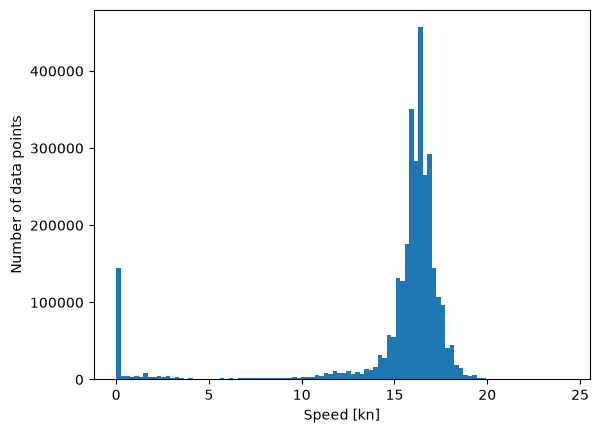

In [10]:
plt.hist(aisdata["speed"], bins=100)
plt.xlabel("Speed [kn]")
plt.ylabel("Number of data points")
plt.show()

## K-Means
We used K-means with 3 clusters, since we expect three operating modes: in port, manoeuvring and transit. We started with speed as the only feature.

In [20]:
km = cluster.KMeans(3, random_state=0)

In [12]:
aisdata["cluster"] = km.fit_predict(aisdata[["speed"]])
aisdata.head()

,date_time_utc,mmsi,dsrc,imo,ship_name,ship_type,lon,lat,status,rot,speed,cog,true_heading,length,breadth,draught,ais_class,date_utc,cluster
0,2025-01-01 00:00:01,219592000,G,8917613,CROWN SEAWAYS,60,10.819025,58.400230,0,-9.0,16.9,155.6,158.0,171,28,6.2,A,2025-01-01,0
1,2025-01-01 00:00:06,219592000,G,8917613,CROWN SEAWAYS,60,10.819285,58.399872,0,-7.0,16.6,158.8,158.0,171,28,6.2,A,2025-01-01,0
2,2025-01-01 00:00:18,219592000,G,8917613,CROWN SEAWAYS,60,10.819842,58.399158,0,-12.0,16.2,158.0,157.0,171,28,6.2,A,2025-01-01,0
3,2025-01-01 00:00:25,219592000,G,8917613,CROWN SEAWAYS,60,10.820135,58.398805,0,8.0,16.5,157.4,157.0,171,28,6.2,A,2025-01-01,0
4,2025-01-01 00:00:31,219592000,G,8917613,CROWN SEAWAYS,60,10.820700,58.398093,0,-5.0,16.9,158.3,157.0,171,28,6.2,A,2025-01-01,0


Speed in each cluster

In [13]:
aisdata.groupby("cluster")["speed"].describe()

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,2724027.0,16.360324,0.831410,14.3,15.8,16.3,16.8,24.3
1,213807.0,0.770965,1.410805,0.0,0.0,0.0,1.2,6.4
2,188463.0,12.055848,1.909658,6.5,11.1,12.4,13.7,14.2


The following method is useful for creating a scatter plot with separate colors for each cluster.

In [14]:
def plot_clusters(df):
    for cluster in sorted(df["cluster"].unique()):
        sub_df = df[df["cluster"]==cluster]
        plt.scatter(sub_df["lon"], sub_df["lat"], s=0.1, label=f"cluster {cluster}")
    plt.legend(loc="upper right")

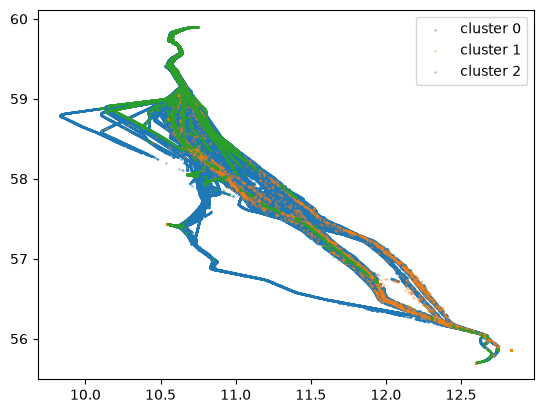

CPU times: user 466 ms, sys: 181 ms, total: 647 ms
Wall time: 678 ms


In [15]:
%%time
plot_clusters(aisdata)
plt.show()

We plotted the speed over time for one day for Nordic Crown, with one color for each cluster.

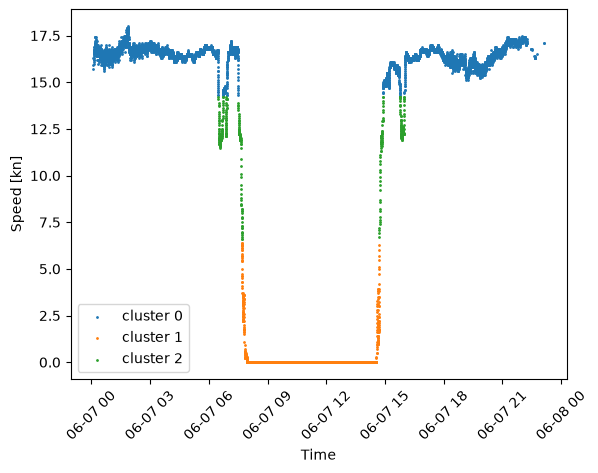

In [16]:
one_day = aisdata[(aisdata['mmsi'] == 219592000) & (aisdata['date_time_utc'] >= '2025-06-07') & (aisdata['date_time_utc'] < '2025-06-08')]

for c in sorted(one_day["cluster"].unique()):
    sub_df = one_day[one_day["cluster"]==c]
    plt.scatter(sub_df["date_time_utc"], sub_df["speed"], s=1, label=f"cluster {c}")
plt.xlabel("Time")
plt.ylabel("Speed [kn]")
plt.xticks(rotation=45)
plt.legend()
plt.show()